# Physical AI 講座 2026 応用編1 第6回 Hands-onをもとに最終課題に手直し
## dora-rs 入門：dataflow を書いて、動かして、いじってみる（想定約10分・Google Colab）

**上から順に Shift+Enter を押すだけ** で動きます。GPU 不要・実機不要。

| Step | 内容 | 目安 |
|---|---|---|
| 0 | dora のインストール | 1分 |
| 1 | 最小の dataflow：タイマー → 2倍 → 表示 | 2分 |
| 2 | センサー → フィルタ → モニタ：NumPy 配列を流す・パラメータを渡す・複数入力を受ける | 3分 |
| 3 | 配線だけ変える：記録ノードを足して、raw と smoothed をプロット | 3分 |
| 宿題 | しきい値で alarm を出すノードを追加する | — |

参考: [dora-rs/dora](https://github.com/dora-rs/dora) ・ [Python guide](https://github.com/dora-rs/dora/blob/main/docs/python-guide.md)


## Step 0. インストール

dora のインストールは `pip install dora-rs-cli` の1行です（CLI + Python API `dora`）。

In [137]:
!pip -q install "dora-rs-cli==1.0.1" "dora-rs==1.0.1" pyarrow numpy pandas matplotlib
import os
os.makedirs("/content/dora_handson", exist_ok=True)
%cd /content/dora_handson
!dora --version

/content/dora_handson
dora-cli 1.0.1


## Step 1. 最小の dataflow：タイマー → 2倍 → 表示

dora のシンプルな構成は **dataflow.yml（どことどこをどう繋げるか）＋ ノード（ただの Python スクリプト）** だけです。

- `nodes:` の 1 ブロック = 1 ノード = 1 プロセス
- `inputs:` は「入力名: 送り元ノード/出力名」。`dora/timer/millis/500` は dora 組込みのタイマー（500ms ごとにイベント）
- ノードは `Node()` でイベントを受け取り、`send_output()` で次のノードへ流す。データは **Apache Arrow 配列**

## Step 2. センサー → フィルタ → モニタ

ロボットらしい形にします。3軸の（ニセ）センサー値を流し、移動平均で平滑化し、モニタが raw と smoothed の両方を受け取ります。

ここで覚えること 3 つ：

1. **NumPy 配列をそのまま流せる** — `pa.array(np_array)` で送り、`event["value"].to_numpy()` で受ける（Arrow はゼロコピーで NumPy / Polars / Torch と相互変換）
2. **パラメータは yaml の `env:` で渡す** — コードを触らず窓幅を変えられる
3. **複数入力は `event["id"]` で見分ける** — 1 ノードが何本でも入力を受けられる

In [138]:
%%writefile dataflow4.yml
nodes:

  - id: sensor
    path: sensor.py
    inputs:
      tick: dora/timer/millis/100
    outputs: [reading]

  - id: filter
    path: filter.py
    env:
      WINDOW: "5"
    inputs:
      reading: sensor/reading
    outputs: [smoothed]

  - id: alarm
    path: alarm.py
    inputs:
      smoothed: filter/smoothed
    outputs: [alarm]

  - id: monitor
    path: monitor.py
    inputs:
      raw: sensor/reading
      smoothed: filter/smoothed
      alarm: alarm/alarm

  - id: recorder
    path: recorder.py
    inputs:
      raw: sensor/reading
      smoothed: filter/smoothed

Overwriting dataflow4.yml


In [139]:
%%writefile alarm.py
import pyarrow as pa
from dora import Node

THRESHOLD = 0.5

node = Node()

for event in node:

    if event["type"] == "INPUT":

        v = event["value"].to_numpy()

        if abs(v[0]) > THRESHOLD:

            node.send_output(
                "alarm",
                pa.array([float(v[0])]),
                metadata=event["metadata"]
            )

    elif event["type"] in ("STOP", "INPUT_CLOSED"):
        break

Overwriting alarm.py


In [140]:
%%writefile sensor.py
import numpy as np
import pyarrow as pa
from dora import Node

node = Node()
rng = np.random.default_rng(0)
N = 30                                   # 30 サンプル送ったら終了（3 秒）
for i, event in enumerate(node):
    if event["type"] != "INPUT":
        break
    t = i / 10
    value = np.array([np.sin(t), np.cos(t), 0.0]) + rng.normal(0, 0.2, 3)   # 3軸 + ノイズ
    node.send_output("reading", pa.array(value.astype(np.float32)), metadata={"t": t})
    if i + 1 >= N:
        break

Overwriting sensor.py


In [141]:
%%writefile filter.py
import os
from collections import deque
import numpy as np
import pyarrow as pa
from dora import Node

WINDOW = int(os.environ.get("WINDOW", "5"))   # yaml の env: から
node = Node()
buf = deque(maxlen=WINDOW)
for event in node:
    if event["type"] == "INPUT":
        buf.append(event["value"].to_numpy())          # Arrow → NumPy
        node.send_output("smoothed", pa.array(np.mean(buf, axis=0)), metadata=event["metadata"])
    elif event["type"] in ("STOP", "INPUT_CLOSED"):
        break

Overwriting filter.py


In [142]:
%%writefile monitor.py
import numpy as np
from dora import Node

node = Node()
closed = set()

for event in node:

    if event["type"] == "INPUT":

        if event["id"] == "alarm":

            print(
                f"🚨 ALARM !!! "
                f"t={event['metadata']['t']:.1f} "
                f"value={event['value'].to_pylist()}",
                flush=True
            )

        else:
            v = event["value"].to_numpy()

            print(
                f"t={event['metadata']['t']:.1f} "
                f"{event['id']:8s} "
                f"{np.round(v, 2)}",
                flush=True
            )

    elif event["type"] == "INPUT_CLOSED":

        closed.add(event["id"])

        if closed == {"raw", "smoothed", "alarm"}:
            break

    elif event["type"] == "STOP":
        break

Overwriting monitor.py


実行前に `dora graph --mermaid` で配線図を出してみます（yaml から自動生成）。

In [143]:
!dora graph dataflow4.yml --mermaid

flowchart TB
  alarm["**alarm**"]
  filter["**filter**"]
  monitor[/"**monitor**"\]
  recorder[/"**recorder**"\]
  sensor["**sensor**"]
subgraph ___dora___ [dora]
  subgraph ___timer_timer___ [timer]
    dora/timer/millis/100[\millis/100/]
  end
end
  filter -- smoothed --> alarm
  sensor -- reading --> filter
  alarm -- alarm --> monitor
  sensor -- reading as raw --> monitor
  filter -- smoothed --> monitor
  sensor -- reading as raw --> recorder
  filter -- smoothed --> recorder
  dora/timer/millis/100 -- tick --> sensor

Paste the above output on https://mermaid.live/ or in a ```mermaid code block on GitHub to display it.


In [144]:
!dora run dataflow4.yml

alarm: DEBUG    building node
filter: DEBUG    building node
monitor: DEBUG    building node
recorder: DEBUG    building node
sensor: DEBUG    building node
15:21:00 DEBUG  alarm: daemon::spawner spawning node
15:21:00 DEBUG  filter: daemon::spawner spawning node
15:21:00 DEBUG  monitor: daemon::spawner spawning node
15:21:00 DEBUG  recorder: daemon::spawner spawning node
15:21:00 DEBUG  sensor: daemon::spawner spawning node
15:21:00 INFO   alarm: spawner spawning: "/usr/bin/python3" -u /content/dora_handson/alarm.py
15:21:01 INFO   filter: spawner spawning: "/usr/bin/python3" -u /content/dora_handson/filter.py
15:21:01 INFO   monitor: spawner spawning: "/usr/bin/python3" -u /content/dora_handson/monitor.py
15:21:01 INFO   recorder: spawner spawning: "/usr/bin/python3" -u /content/dora_handson/recorder.py
15:21:01 INFO   sensor: spawner spawning: "/usr/bin/python3" -u /content/dora_handson/sensor.py

15:21:01 INFO   [dora]: dora daemon finished building nodes, spawning...

15:21:01 INF

## Step 3. 記録ノードを足して可視化

sensor / filter は **そのまま** で、yaml に `recorder` を 1 ノード足すだけで raw と smoothed を CSV に残せます。
（dora には `dora record` / `dora replay` という rosbag 相当の機能もあります）

In [145]:
%%writefile recorder.py
import csv
from dora import Node

node = Node()
rows = {}                                    # t → {"raw": [...], "smoothed": [...]}
closed = set()
for event in node:
    if event["type"] == "INPUT":
        t = round(event["metadata"]["t"], 3)           # 浮動小数のキー揺れを防ぐ
        rows.setdefault(t, {})[event["id"]] = event["value"].to_pylist()
    elif event["type"] == "INPUT_CLOSED":
        closed.add(event["id"])
        if closed == {"raw", "smoothed"}:
            break
    elif event["type"] == "STOP":
        break

with open("log.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["t", "raw_x", "raw_y", "raw_z", "smooth_x", "smooth_y", "smooth_z"])
    for t in sorted(rows):
        r = rows[t]
        if "raw" in r and "smoothed" in r:
            w.writerow([t, *r["raw"], *r["smoothed"]])
print("wrote log.csv:", len(rows), "rows", flush=True)

Overwriting recorder.py


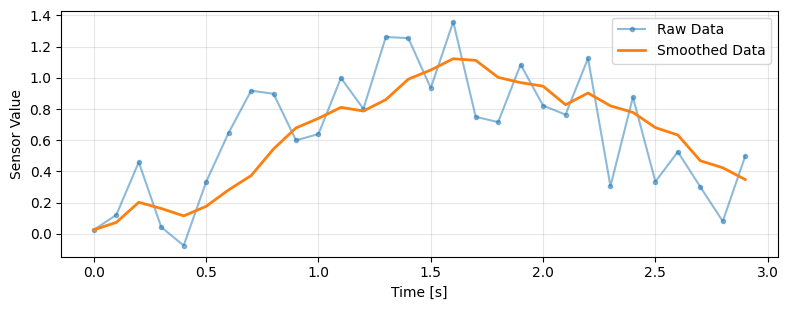

In [146]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("log.csv")

fig, ax = plt.subplots(figsize=(8, 3.2))

ax.plot(df.t, df.raw_x,
        ".-",
        alpha=0.5,
        label="Raw Data")

ax.plot(df.t, df.smooth_x,
        "-",
        lw=2,
        label="Smoothed Data")

ax.set_xlabel("Time [s]")
ax.set_ylabel("Sensor Value")
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig("plot.png", dpi=120)

plt.show()

やったことをまとめると：

- **ノード = Python スクリプト**（`Node()` → イベントループ → `send_output()`）
- **dataflow.yml = 配線とパラメータ**。ノードを足す・入れ替える・窓幅を変えるのは yaml だけ
- **データは Arrow 配列**。NumPy とゼロコピーで行き来できる（画像や関節角も同じ形で流れる）

実際のロボット（OpenArm）でも、`sensor` が「アームやカメラのドライバ」、`filter` が「IK や推論」、`recorder` が「データセット recorder」になるだけで、形はまったく同じです。

## 宿題：alarm ノードを追加する

`filter/smoothed` を受け取り、`|x| > 0.8` のときだけ `alarm` を出力するノード `alarm.py` を書き、`monitor` が `alarm` も受け取って表示するように配線してください。
（ヒント：`monitor.py` の `closed == {...}` に `"alarm"` を足すのを忘れずに）

In [147]:
%%writefile alarm.py
import numpy as np
import pyarrow as pa
from dora import Node

THRESHOLD = 0.5
node = Node()
for event in node:
    if event["type"] == "INPUT":

        v = event["value"].to_numpy()

        if abs(v[0]) > THRESHOLD:
            node.send_output(
                "alarm",
                pa.array([float(v[0])]),
                metadata=event["metadata"]
            )

    elif event["type"] in ("STOP", "INPUT_CLOSED"):
        break

Overwriting alarm.py
